# Eight sites

[← All examples](../paper_examples.ipynb) · [Python analysis](../../tutorials/eight_slots_analysis.py) · [Model inputs](../../examples/eight-slots/model.json)

One occupied-slot query, three possible topologies, one symbolic ODE.


<nav class="example-sections" aria-label="Example sections" style="display:flex;align-items:stretch;gap:5px;flex-wrap:wrap;margin:16px auto;padding-top:8px;padding-bottom:8px;border-bottom:1px solid #cddce1"><span data-topic="rules" style="background:#e7f3e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=59f489f7" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">1 · Rules &amp; state space</a></span><span data-topic="inputs" style="background:#fbe9e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=41ad6a7b" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">2 · Inputs &amp; semantics</a></span><span data-topic="observables" style="background:#e8f0fb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=6ed622b6" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">3 · Observable discovery</a></span><span data-topic="ode" style="background:#f0eafb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap">4 · <a href="#cell-id=e3460488" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">ODE</a> &amp; <a href="https://stochmech.algochem.techfak.de/experiments/eight-slots/index.html#pjc" target="_blank" rel="noopener noreferrer" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">pJC ↗ Web</a></span><span data-topic="initial" style="background:#e3f3f0;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=5cfa56c7" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">5 · Initial states</a></span><span data-topic="dynamics" style="background:#fff0de;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=f4ad9499" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">6 · Dynamics</a></span></nav>

In [1]:
from pathlib import Path
import sys
PACKAGE = next(p for p in (Path.cwd(), *Path.cwd().parents)
               if (p / "src/mfobs").is_dir())
NOTEBOOKS = PACKAGE / "notebooks"
sys.path[:0] = [str(NOTEBOOKS), str(PACKAGE / "src"), str(PACKAGE)]
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import visual_view as visual
import visual_suite as suite

run = visual.Run("visual-05_eight_slots")

<h2 id="rules" style="background:#e7f3e9;padding:12px 16px;border-radius:5px">1 · Rules & state space</h2>

Each site owns one binding slot. Eight sites form a simple undirected graph of degree two, giving the possible topologies 8, 4+4 and 3+5.


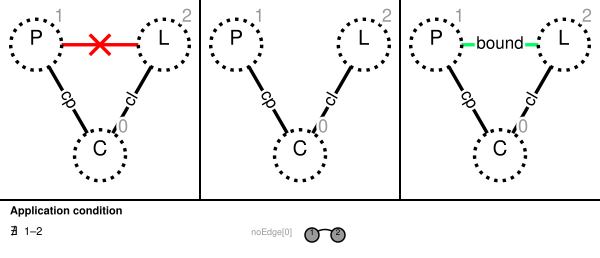

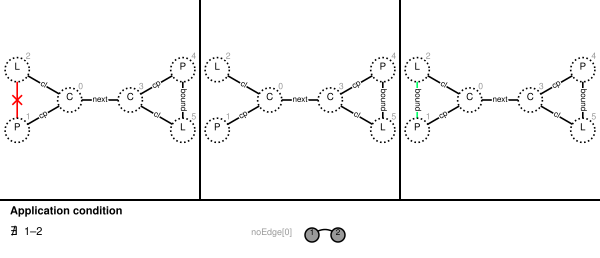

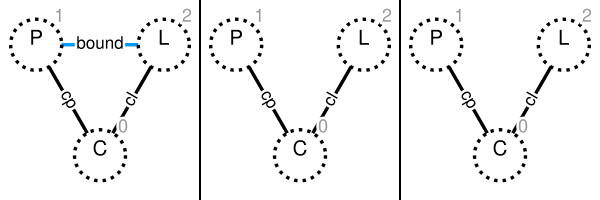

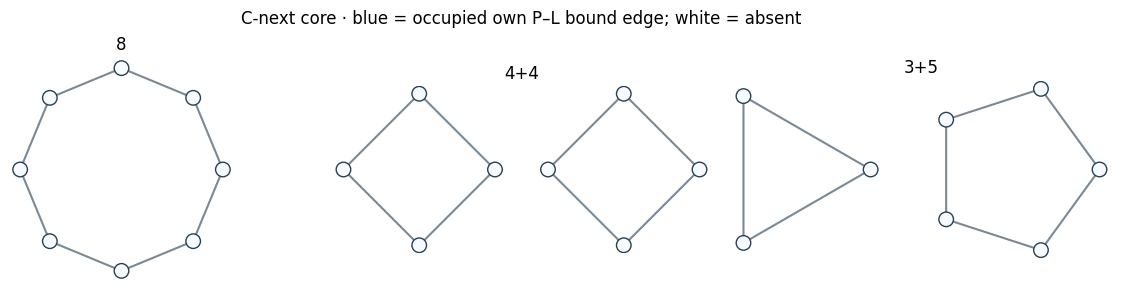

In [2]:
from mfobs import analyze as analyze_model
from mfobs.applications import EightSlots
backend = EightSlots()
defaults = backend.specification()
Omega = defaults.omega
rules = defaults.rules
observables = defaults.observables
from mfobs import ModelInputs
inputs = ModelInputs(Omega, rules, observables)
visual.rules(list(inputs.rule_gmls().items()))
suite.topology_picture((0,) * 8)

<h2 id="inputs" style="background:#fbe9e9;padding:12px 16px;border-radius:5px">2 · Inputs & semantics</h2>

P0 counts occupied own P–L bound edges. This is the sole input observable.

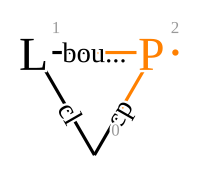

In [3]:
query = inputs.query_gmls()["P0"]
visual.rules([("P0 · occupied slot", query)], identity=True)

<h2 id="observables" style="background:#e8f0fb;padding:12px 16px;border-radius:5px">3 · Observable discovery</h2>

Compose the rules with the query and reduce the resulting counts using the graph-family invariants.


In [4]:
MAX_EXPANSIONS = 100
result = analyze_model(inputs, backend=backend, max_expansions=MAX_EXPANSIONS).record()

print("Closure:", result["status"])
print("Coordinates:", len(result["basis"]))
suite.gml_table(result["identity_patterns"])


Closure: CLOSED_MODULO_EIGHT_SLOT_AXIOMS
Coordinates: 48


Count,Pattern,Meaning
P0,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22locally-normalized-count%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22L%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22cp%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%202%20label%20%22cl%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22bound%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",1 (occupied)
P1,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22locally-normalized-count%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22L%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22cp%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%202%20label%20%22cl%22%20%5D%0A%09%5D%0A%09constrainNoEdge%20%5B%0A%09%09source%201%0A%09%09target%202%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry","{'C3:000': Fraction(1, 2), 'C3:001': Fraction(-1, 2), 'C4:0000': Fraction(1, 2), 'C4:0001': Fraction(-1, 2), 'C5:00000': Fraction(1, 2), 'C5:00001': Fraction(-1, 2), 'C8:00000000': Fraction(1, 2), 'C8:00000001': Fraction(-1, 2)}"
P2,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22locally-normalized-count%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22L%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22L%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22cp%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%202%20label%20%22cl%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%203%20label%20%22next%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22cp%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%205%20label%20%22cl%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22bound%22%20%5D%0A%09%5D%0A%09constrainNoEdge%20%5B%0A%09%09source%201%0A%09%09target%202%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry","{'C3:001': Fraction(1, 1), 'C3:011': Fraction(-1, 1), 'C4:0001': Fraction(1, 1), 'C4:0011': Fraction(-1, 1), 'C5:00001': Fraction(1, 1), 'C5:00011': Fraction(-1, 1), 'C8:00000001': Fraction(1, 1), 'C8:00000011': Fraction(-1, 1)}"
P3,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22locally-normalized-count%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22L%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22L%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22L%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22cp%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%202%20label%20%22cl%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%203%20label%20%22next%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%206%20label%20%22next%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22cp%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%205%20label%20%22cl%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22bound%22%20%5D%0A%09%09edge%20%5B%20source%206%20target%207%20label%20%22cp%22%20%5D%0A%09%09edge%20%5B%20source%206

<h2 id="ode" style="background:#f0eafb;padding:12px 16px;border-radius:5px">4 · ODE</h2>

The generated system has 48 coordinates.


In [5]:
suite.coefficient_equations(result, names=('P0', 'P1'))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<h2 id="initial" style="background:#e3f3f0;padding:12px 16px;border-radius:5px">5 · Initial states</h2>

Now choose occupancy, after synthesis. The same eight-bit pattern is placed on each topology; the complete coordinate vector is evaluated separately.

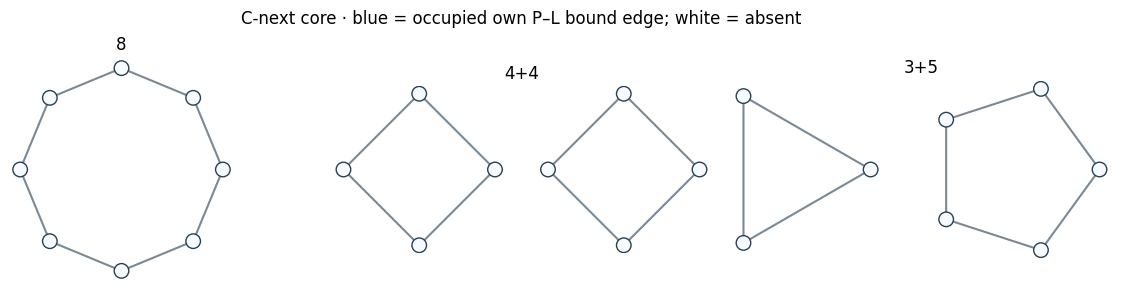

,Topology,P1,P6,P10,P17
0,8,8.0,0.0,0.0,0.0
1,4+4,8.0,0.0,16.0,0.0
2,3+5,8.0,6.0,0.0,10.0


In [6]:
BITS = (0, 0, 0, 0, 0, 0, 0, 0)
initial = suite.eight_initial(result, BITS)
suite.topology_picture(BITS)
shown = [name for name in result["basis"] if any(row[name] for row in initial.values())]
visual.table([{"Topology": tag, **{name: row[name] for name in shown}}
              for tag, row in initial.items()])

<h2 id="dynamics" style="background:#fff0de;padding:12px 16px;border-radius:5px">6 · Dynamics</h2>

Integrate the same generated 48-coordinate system with three different initial vectors.

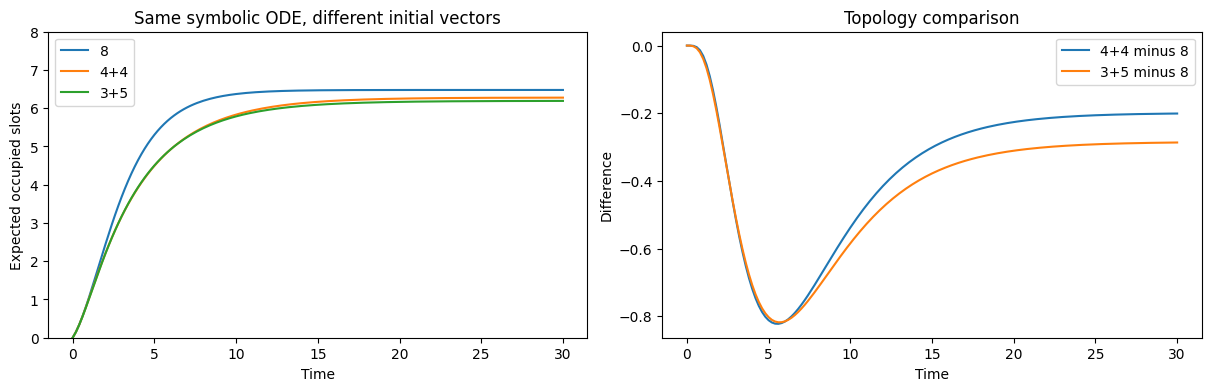

VBox(children=(FloatSlider(value=0.08, continuous_update=False, description='basal_bind', max=2.0, step=0.05),…

In [7]:
T = 30.0
rates = {'basal_bind': 0.08, 'cooperative_bind': 1.2, 'unbind': 0.4}
curves = suite.eight_curves(result, initial, rates, end=T)
controls = suite.rate_controls(lambda rates, **opts: suite.eight_curves(result, initial, rates, **opts), rates, curves['options'])

[← All examples](../paper_examples.ipynb)